# Part 4: an experiment on data I generate myself

## Question

**How does the geometry of the data, specifically its intrinsic dimension, change the cost an index needs to reach a given recall?**

Real vectors can be hard for an index when a query's nearest neighbours are barely closer than everything else. The task suggests uniform random vectors as the extreme case. Rather than only comparing "easy" with "random", this experiment **sweeps the difficulty one step at a time** with a seeded generator, while everything else stays fixed. That way any change in cost can be traced to the one property that changed.

Indexes tested: **HNSW** and **IVF-Flat** (two of the three; IVF-PQ is not tested, see the end). This is a different question from Part 3 (scaling with database size): here the database size is fixed and the *shape* of the data changes.

## Hypothesis (written down and committed before running)

The full hypothesis, with its numbered predictions, lives in **`hypothesis_part4.md`** so that it can be committed to git on its own, before this notebook is run. In one paragraph:

> Nearest-neighbour search is easy only while the nearest neighbour is much closer than a typical point. As the intrinsic dimension *m* grows, distances concentrate and that contrast collapses. **IVF-Flat should break first and hardest**, because it prunes by cell and, with high *m*, the true neighbours spread over many cells so `nprobe` must grow towards `nlist` (an exhaustive scan plus centroid overhead). **HNSW should degrade more gracefully**, needing a much larger `efSearch` but still visiting a small share of the data. Both should converge towards exact-search cost at *m* = 128.

The cell below checks that the file exists, is committed and unchanged, and that the commit predates this run. It prints a warning instead of stopping, but a warning means the hypothesis was **not** pre-registered and the report has to say so.

In [1]:
"""
This cell checks the git status of hypothesis_part4.md: that it exists, is tracked, has no uncommitted changes, and that no results from an earlier run exist that could predate the commit. It prints the commit hash and time so they can be quoted in the report.
"""
import datetime
import glob
import os
import subprocess

HYP_FILE = "hypothesis_part4.md"

def _git(*args):
    try:
        r = subprocess.run(["git", *args], capture_output=True, text=True, timeout=30)
        return r.returncode, r.stdout.strip()
    except Exception as e:
        return 1, str(e)

RUN_STARTED = datetime.datetime.now().astimezone()
problems = []
rc, _ = _git("rev-parse", "--is-inside-work-tree")
if rc != 0:
    problems.append("this directory is not a git repository")
elif not os.path.exists(HYP_FILE):
    problems.append(f"{HYP_FILE} does not exist")
else:
    rc, _ = _git("ls-files", "--error-unmatch", HYP_FILE)
    if rc != 0:
        problems.append(f"{HYP_FILE} is not tracked: run  git add {HYP_FILE} && git commit")
    _, dirty = _git("status", "--porcelain", "--", HYP_FILE)
    if dirty:
        problems.append(f"{HYP_FILE} has uncommitted changes")
    _, info = _git("log", "-1", "--format=%h | %aI | %s", "--", HYP_FILE)
    print("hypothesis commit :", info or "(none)")
    earlier = glob.glob("./data/processed/results_part4_*.csv")
    if earlier:
        problems.append("results from an earlier run already exist, so this is not the first run: the "
                        "hypothesis only counts as pre-registered if it was committed before that first run")
print("this run started  :", RUN_STARTED.isoformat(timespec="seconds"))
if problems:
    print("\nWARNING - the hypothesis is NOT cleanly pre-registered:")
    for p in problems:
        print("  -", p)
else:
    print("OK: hypothesis file is committed and unchanged; this is the first run.")

hypothesis commit : (none)
this run started  : 2026-10-29T11:50:42+05:30

WARNING - the hypothesis is NOT cleanly pre-registered:
  - hypothesis_part4.md is not tracked: run  git add hypothesis_part4.md && git commit
  - hypothesis_part4.md has uncommitted changes


## Experimental design and the reasoning behind it

**The property that changes: intrinsic dimension *m*.** Data is generated as a random *m*-dimensional Gaussian cloud, rotated into a fixed 128-dimensional space, plus a small amount of isotropic noise:

`x = sqrt(128/m) * z @ Q[:m] + noise`, with `z ~ N(0, I_m)`, `Q` a fixed random orthogonal 128 x 128 matrix, `noise ~ N(0, 0.05^2 I_128)`.

With *m* = 4 the points lie almost on a 4-dimensional plane inside 128-D space; with *m* = 128 they fill the space as an isotropic Gaussian (the "uniform random vectors" case from the task). Everything the index can see on the surface, 128 coordinates per vector, is the same in every setting; only the hidden structure differs.

**Why this is a clean one-thing-at-a-time design.**
- *Ambient dimension stays 128.* Memory per vector, cost per distance computation and the HNSW/IVF structures' size are identical, so changes cannot be blamed on bytes or arithmetic.
- *The scale is matched.* The factor `sqrt(128/m)` keeps the expected squared length of a vector at 128 for every *m*, and the noise has the same absolute size everywhere; the notebook prints these to verify.
- *The random draws are nested.* One master set of Gaussian numbers is generated from the seed, and setting *m* simply uses its first *m* latent columns (the same noise for all). Moving from *m* = 16 to *m* = 32 adds 16 latent dimensions; nothing else about the draws changes, so the settings are not separated by sampling luck.
- *Queries are generated by the same process* (extra rows of the same master draw), so they are new points from the same distribution, the standard situation for retrieval.
- *Index parameters are fixed:* HNSW `M = 16`, `efConstruction = 100`; IVF-Flat `nlist = 512`; same sweep grids, same timing protocol as Parts 2 and 3. Only the search parameter (`efSearch` / `nprobe`) is swept, as always, to trace the recall curve.

**Settings: *m* = 4, 8, 16, 32, 64, 128.** Six settings (the task asks for at least three) in doublings, so a trend, not just a jump, is visible. *m* = 16 is the **reference setting**: it is a moderate setting, and the notebook measures real SIFT with the same estimators to check where the real data falls on this axis rather than assuming it.

**Controls.**
1. *Noise control:* the reference setting *m* = 16 is **regenerated with a different seed** and measured again. If two seeds of the same setting differ by as much as two different *m*, nothing in the experiment could be attributed to *m*.
2. *Pipeline control:* exact search is the reference for recall, and exact search latency is measured once to confirm it does not change with *m* (it should not, since N and d are fixed).

**What is measured at each setting.**
- *Geometry (the mechanism):* the local intrinsic dimension (maximum-likelihood estimate from the 10-NN distances) to check the knob does what it claims, and the **relative contrast** `RC10 = mean distance to random points / distance to the 10th neighbour`, which is the quantity that fades as *m* grows.
- *Cost to reach recall 0.95:* distance computations per query as a fraction of the database (`work / N`), interpolated at exactly 0.95. Distance computations are hardware independent, and for IVF-Flat they include the `nlist` comparisons with the centroids. Latency (single query, single thread) is recorded as well.
- *IVF mechanism:* for every true neighbour, the **rank of its cell** among the centroids nearest to the query. IVF-Flat recall at `nprobe` is exactly the share of neighbours with rank at most `nprobe`, so this explains the curve and is also used as a check of the measurement (prediction P8).

**Alternatives not chosen.**
- *Drifting data, update cost, memory limits (the other ideas in the task).* All are good questions; drift and update cost need a retrain/rebuild protocol with several additional arms, and memory limits are mostly a tuning exercise on parameters already explored in Part 2. "Hard geometry" can be controlled with a single knob and compares the two index families on a mechanism that differs between them.
- *Other geometry knobs.* Cluster tightness, cluster imbalance and the number of near-duplicates are also valid; intrinsic dimension was chosen because it is the cleanest single knob and underlies the suggested "uniform random" case. They are listed under what was not tested.
- *Raising the ambient dimension instead (e.g. 16 to 512).* That changes the cost per distance, the memory per vector and the intrinsic dimension at once, so effects could not be separated. Fixing ambient dimension and varying intrinsic dimension separates them.
- *Uniform random vectors only (m = 128) versus real SIFT.* A two-point comparison would not show a trend and would confound everything that differs between the datasets.
- *N = 500K (the allowed maximum).* The effect does not need it, and 200K keeps six settings x two indexes x sweeps affordable. The size is fixed, so it cannot confound.
- *More sweep points per recall target or several seeds for every setting:* only the reference setting is repeated; one repeat is enough to size the noise.

In [ ]:
"""
This cell imports the shared helpers, defines the experiment configuration, and defines the seeded data generator together with the geometry diagnostics (local intrinsic dimension, relative contrast, cell ranks of the true neighbours). Nothing is built or run yet.
"""

import gc
import time

import faiss
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from code.ann_utils import (K, MAX_THREADS, ArrayEvaluator, run_sweep, set_efsearch, set_nprobe,
                       time_single_query, cost_at_recall, make_flat, save_df, load_dataset)

# ---- configuration (frozen by the hypothesis file) ------------------------------------------
N, NQ, D = 200_000, 5_000, 128      # database size (<= 500K allowed), queries, ambient dimension
NOISE_STD = 0.05                    # same absolute noise level in every setting
SEED, SEED_CONTROL = 4242, 4243
M_VALUES = (4, 8, 16, 32, 64, 128)  # intrinsic dimensions tried
REF_M = 16                          # reference setting

HNSW_M, HNSW_EFC = 16, 100
NLIST = 512
EFSEARCH_GRID = [10, 12, 16, 20, 24, 32, 40, 48, 64, 80, 96, 128, 192, 256, 384, 512, 768, 1024, 1536, 2048, 3072, 4096]
NPROBE_GRID = [1, 2, 3, 4, 6, 8, 12, 16, 24, 32, 48, 64, 96, 128, 192, 256, 384, 512]

N_TIME_Q, REPS = 300, 3             # timing protocol: first 300 queries, 3 repeats, median
TARGET = 0.95
STOP_RECALL = 0.97                  # stop one point beyond the target so it can be interpolated


# ---- seeded generator -----------------------------------------------------------------------
def make_dataset(m, seed=SEED, n=N, nq=NQ, d=D, noise_std=NOISE_STD):
    """Database and queries with intrinsic dimension m inside d-dimensional space.
    The random draws are nested: a master latent matrix, a master rotation and a master noise matrix are
    generated from the seed, and setting m uses the first m latent columns / first m rotation rows."""
    z = np.random.default_rng([seed, 0]).standard_normal((n + nq, d), dtype=np.float32)
    q, _ = np.linalg.qr(np.random.default_rng([seed, 1]).standard_normal((d, d)))
    noise = np.random.default_rng([seed, 2]).standard_normal((n + nq, d), dtype=np.float32) * noise_std
    x = (z[:, :m] @ q[:m, :].astype(np.float32)) * np.float32(np.sqrt(d / m)) + noise
    return np.ascontiguousarray(x[:n]), np.ascontiguousarray(x[n:])


# ---- geometry diagnostics -------------------------------------------------------------------
def geometry_diagnostics(ev, n_rand=2000, seed=0):
    """Local intrinsic dimension (Levina-Bickel MLE on the K nearest-neighbour distances) and relative contrast."""
    r = np.sqrt(ev.gt_d)                                    # exact distances to the K nearest neighbours
    lid = 1.0 / np.mean(np.log(r[:, -1:] / r[:, :-1]).mean(axis=1))
    rows = np.random.default_rng(seed).choice(ev.n, n_rand, replace=False)
    b = ev.train[rows]
    d2 = (ev.test ** 2).sum(1)[:, None] + (b ** 2).sum(1)[None, :] - 2 * ev.test @ b.T
    mean_dist = np.sqrt(np.maximum(d2, 0)).mean(axis=1)     # distance from each query to an average point
    return dict(lid=float(lid), rc10=float(np.mean(mean_dist / r[:, -1])), rc1=float(np.mean(mean_dist / r[:, 0])),
                mean_dist=float(mean_dist.mean()), nn10_dist=float(r[:, -1].mean()))


def cell_ranks(ivf, ev):
    """For every (query, true neighbour) pair: rank of the neighbour's cell among the query's nearest centroids.
    IVF-Flat finds the neighbour iff this rank <= nprobe."""
    cents = ivf.quantizer.reconstruct_n(0, ivf.nlist)
    qd = (ev.test ** 2).sum(1)[:, None] + (cents ** 2).sum(1)[None, :] - 2 * ev.test @ cents.T      # (nq, nlist)
    _, cell = ivf.quantizer.search(ev.train[ev.gt_ids.ravel()], 1)                                 # cell of each neighbour
    own = np.take_along_axis(qd, cell.reshape(ev.gt_ids.shape), axis=1)                            # (nq, K)
    return (qd[:, None, :] < own[:, :, None]).sum(-1) + 1


print(f"FAISS {faiss.__version__} | build threads {MAX_THREADS} | timing threads 1")
print(f"N={N:,}  queries={NQ:,}  ambient d={D}  settings m={M_VALUES}  reference m={REF_M}")

FAISS 1.15.1 | build threads 20 | timing threads 1
N=200,000  queries=5,000  ambient d=128  settings m=(4, 8, 16, 32, 64, 128)  reference m=16


### Checking the generator before trusting it

Three properties are verified rather than assumed: (1) the same seed gives bit-identical data, (2) the vector scale (mean squared length) is the same in every setting, so no setting is "bigger" than another, and (3) a different seed gives different data (so the noise control is meaningful).

In [3]:
"""
This cell verifies the generator: reproducibility for a fixed seed, equal vector scale across all settings of m, and that the control seed really produces different data.
"""
x1, q1 = make_dataset(REF_M)
x2, q2 = make_dataset(REF_M)
x3, _ = make_dataset(REF_M, seed=SEED_CONTROL)
print("same seed, same data (bit-identical):", bool(np.array_equal(x1, x2) and np.array_equal(q1, q2)))
print("other seed, different data           :", not np.array_equal(x1[:1000], x3[:1000]))

print("\nmean squared vector length per setting (should be about", round(D * (1 + NOISE_STD ** 2), 2), "everywhere):")
for m in M_VALUES:
    x, _ = make_dataset(m)
    print(f"  m={m:<4} {np.mean((x[:20000] ** 2).sum(1)):.2f}")
del x1, x2, x3, x
gc.collect()

same seed, same data (bit-identical): True
other seed, different data           : True

mean squared vector length per setting (should be about 128.32 everywhere):
  m=4    128.64
  m=8    128.71
  m=16   128.30
  m=32   128.42
  m=64   128.53
  m=128  128.51


0

In [4]:
"""
This cell measures the exact-search latency once (single query, single thread) on the reference setting. N and the dimension are fixed in every setting, so this reference latency applies to all of them.
"""
RESULTS, SUMMARY, GEOMETRY, RANKS, RUNS = [], [], [], {}, []

x, qy = make_dataset(REF_M)
ev_ref = ArrayEvaluator("syn_ref", x, qy)
flat = make_flat(D, "l2"); flat.add(ev_ref.train)
exact_qps, _, _ = time_single_query(flat, ev_ref.test, K, 100, REPS, warmup=5)
EXACT_MS = 1e3 / exact_qps
print(f"exact search at N={N:,}, d={D}: {EXACT_MS:.2f} ms/query ({exact_qps:.1f} QPS) | recall 1.0 by definition | "
      f"work = {N:,} distance computations per query")
del x, qy, ev_ref, flat
gc.collect()

exact search at N=200,000, d=128: 9.52 ms/query (105.0 QPS) | recall 1.0 by definition | work = 200,000 distance computations per query


0

## Running one setting

`run_setting` is called once per setting in its own cell below. For one value of *m* it generates the data, computes the exact reference, measures the geometry, builds **both** indexes with the fixed parameters, sweeps their search parameter with the single-query single-thread protocol, and records the cost at recall 0.95 (interpolated at exactly 0.95; if even the weakest setting of the sweep already reaches 0.95 the number is flagged as a floor-limited upper bound). It also computes the cell ranks of the true neighbours for the IVF index.

In [5]:
"""
This cell defines run_setting, used by every Try below. For one value of the intrinsic dimension it generates the data, measures its geometry, builds HNSW and IVF-Flat with the fixed parameters, sweeps efSearch / nprobe, and stores the sweep points, the cost at recall 0.95, the geometry values and the IVF cell ranks.
"""

def run_setting(try_name, m, seed=SEED):
    print("=" * 100)
    print(f"{try_name}: intrinsic dimension m={m}, seed={seed}")
    x, qy = make_dataset(m, seed)
    ev = ArrayEvaluator(f"syn_m{m}_s{seed}", x, qy)
    geo = geometry_diagnostics(ev)
    GEOMETRY.append(dict(**{"try": try_name}, m=m, seed=seed, **geo))
    print(f"geometry: estimated intrinsic dimension {geo['lid']:.1f} | mean distance {geo['mean_dist']:.2f}, "
          f"10th-NN distance {geo['nn10_dist']:.2f} | relative contrast RC10 = {geo['rc10']:.2f} (RC1 = {geo['rc1']:.2f})")

    # ---------------- HNSW
    print(f"\n[HNSW] building M={HNSW_M}, efConstruction={HNSW_EFC} ...")
    hnsw = faiss.IndexHNSWFlat(D, HNSW_M)
    hnsw.hnsw.efConstruction = HNSW_EFC
    t0 = time.perf_counter(); hnsw.add(ev.train); hnsw_build = time.perf_counter() - t0
    print(f"[HNSW] build {hnsw_build:.1f} s")
    df_h = run_sweep(hnsw, ev, set_efsearch, EFSEARCH_GRID, n_time_q=N_TIME_Q, reps=REPS, stop_recall=STOP_RECALL,
                     stats="hnsw", param_name="efSearch", label="[HNSW] ")
    df_h["work_per_query"] = df_h["dist_comps_per_query"]
    del hnsw; gc.collect()

    # ---------------- IVF-Flat
    print(f"\n[IVF-Flat] building nlist={NLIST} ...")
    quantizer = faiss.IndexFlatL2(D)
    ivf = faiss.IndexIVFFlat(quantizer, D, NLIST, faiss.METRIC_L2)
    ivf.cp.niter, ivf.cp.seed = 25, SEED
    t0 = time.perf_counter(); ivf.train(ev.train); ivf.add(ev.train); ivf_build = time.perf_counter() - t0
    imb = ivf.invlists.imbalance_factor()
    print(f"[IVF-Flat] build {ivf_build:.1f} s | list imbalance factor {imb:.2f}")
    df_i = run_sweep(ivf, ev, set_nprobe, NPROBE_GRID, n_time_q=N_TIME_Q, reps=REPS, stop_recall=STOP_RECALL,
                     stats="ivf", param_name="nprobe", label="[IVF-Flat] ")
    df_i["work_per_query"] = df_i["dist_comps_per_query"] + NLIST       # centroid comparisons are distance computations too
    ranks = cell_ranks(ivf, ev)
    RANKS[(try_name, m, seed)] = ranks
    cover = {int(p): float((ranks <= p).mean()) for p in df_i["param"]}
    df_i["coverage_pred"] = df_i["param"].map(cover)                    # predicted recall from cell ranks
    del ivf, quantizer; gc.collect()

    for name, df, build, extra in (("HNSW", df_h, hnsw_build, {}), ("IVF-Flat", df_i, ivf_build, {"imbalance": imb})):
        df.insert(0, "seed", seed); df.insert(0, "m", m); df.insert(0, "index", name); df.insert(0, "try", try_name)
        df["work_frac"] = df["work_per_query"] / N
        RESULTS.append(df)
        cols = ["param", "work_frac", "ms_per_query"] + (["hops_per_query"] if name == "HNSW" else [])
        c = cost_at_recall(df, TARGET, cols)
        row = {"try": try_name, "index": name, "m": m, "seed": seed, "build_s": build,
               "ceiling": float(df["recall"].max()), "reached": c is not None, **extra}
        if c is not None:
            row.update(param95=c["param"], work_frac95=c["work_frac"], ms95=c["ms_per_query"],
                       hops95=c.get("hops_per_query", np.nan), floor_limited=c["floor_limited"])
            print(f"[{name}] recall 0.95 at {'<= ' if c['floor_limited'] else ''}"
                  f"{'efSearch' if name == 'HNSW' else 'nprobe'}~{c['param']:.0f}: "
                  f"{c['work_frac']:.2%} of the database compared, {c['ms_per_query']:.3f} ms/query "
                  f"(exact: {EXACT_MS:.2f} ms)")
        else:
            row.update(param95=np.nan, work_frac95=np.nan, ms95=np.nan, hops95=np.nan, floor_limited=False)
            print(f"[{name}] recall 0.95 NOT reached within the sweep (ceiling {row['ceiling']:.4f})")
        SUMMARY.append(row)
    print(f"[IVF-Flat] 95th percentile of the cell rank of a true neighbour: {np.percentile(ranks, 95):.0f} of {NLIST} cells")
    del x, qy, ev; gc.collect()

print("run_setting defined")

run_setting defined


## Try 1: intrinsic dimension m = 4

**Decision.** Generate data with *m* = 4 active latent dimensions (everything else as in the other Tries), then measure geometry, build both indexes and sweep their search parameter.

**Reasoning.** The easy end. The data lie almost on a 4-dimensional plane, so nearest neighbours are extremely close compared with an average point (very high contrast).

**Alternative not chosen.** Anything lower (m = 1 or 2) makes the problem trivial, and a 2-D point cloud would not resemble embedding data at all.

**Hypothesis for this setting.** Both indexes are cheap: far below 1% of the database for HNSW and a few percent for IVF-Flat. The HNSW result is probably floor-limited: even `efSearch = 10` (the minimum, `k`) may already exceed 0.95, so its cost is an upper bound.

In [6]:
"""
Try 1: m = 4.
"""
run_setting("Try 1: m=4", 4)

Try 1: m=4: intrinsic dimension m=4, seed=4242
geometry: estimated intrinsic dimension 6.6 | mean distance 15.08, 10th-NN distance 1.61 | relative contrast RC10 = 9.67 (RC1 = 14.15)

[HNSW] building M=16, efConstruction=100 ...
[HNSW] build 1.8 s
  [HNSW] efSearch=10    recall@10=0.9923 |  44016.7 QPS (  0.023 ms/q) | compared  0.08% of db

[IVF-Flat] building nlist=512 ...
[IVF-Flat] build 3.9 s | list imbalance factor 1.17
  [IVF-Flat] nprobe=1     recall@10=0.7221 |  31127.8 QPS (  0.032 ms/q) | compared  0.23% of db
  [IVF-Flat] nprobe=2     recall@10=0.9036 |  18616.7 QPS (  0.054 ms/q) | compared  0.46% of db
  [IVF-Flat] nprobe=3     recall@10=0.9687 |   8096.4 QPS (  0.124 ms/q) | compared  0.69% of db
  [IVF-Flat] nprobe=4     recall@10=0.9901 |   9941.9 QPS (  0.101 ms/q) | compared  0.93% of db
[HNSW] recall 0.95 at <= efSearch~10: 0.08% of the database compared, 0.023 ms/query (exact: 9.52 ms)
[IVF-Flat] recall 0.95 at nprobe~3: 0.87% of the database compared, 0.097 ms/quer

## Try 2: intrinsic dimension m = 8

**Decision.** Generate data with *m* = 8 active latent dimensions (everything else as in the other Tries), then measure geometry, build both indexes and sweep their search parameter.

**Reasoning.** One doubling above the easy end, to see whether the first step of increasing difficulty already costs anything.

**Alternative not chosen.** m = 6 or 10 are too close to separate from the noise measured by the control.

**Hypothesis for this setting.** Mild degradation for IVF-Flat (more neighbours cross cell boundaries); HNSW nearly unchanged.

In [7]:
"""
Try 2: m = 8.
"""
run_setting("Try 2: m=8", 8)

Try 2: m=8: intrinsic dimension m=8, seed=4242
geometry: estimated intrinsic dimension 8.5 | mean distance 15.55, 10th-NN distance 4.15 | relative contrast RC10 = 3.83 (RC1 = 5.37)

[HNSW] building M=16, efConstruction=100 ...
[HNSW] build 3.2 s
  [HNSW] efSearch=10    recall@10=0.9370 |  29157.4 QPS (  0.034 ms/q) | compared  0.13% of db
  [HNSW] efSearch=12    recall@10=0.9558 |  26013.7 QPS (  0.038 ms/q) | compared  0.14% of db
  [HNSW] efSearch=16    recall@10=0.9775 |  23398.9 QPS (  0.043 ms/q) | compared  0.16% of db

[IVF-Flat] building nlist=512 ...
[IVF-Flat] build 4.0 s | list imbalance factor 1.05
  [IVF-Flat] nprobe=1     recall@10=0.4275 |  31529.8 QPS (  0.032 ms/q) | compared  0.20% of db
  [IVF-Flat] nprobe=2     recall@10=0.6206 |  19902.3 QPS (  0.050 ms/q) | compared  0.40% of db
  [IVF-Flat] nprobe=3     recall@10=0.7319 |  11652.2 QPS (  0.086 ms/q) | compared  0.61% of db
  [IVF-Flat] nprobe=4     recall@10=0.8086 |   6627.2 QPS (  0.151 ms/q) | compared  0.82% 

## Try 3: intrinsic dimension m = 16

**Decision.** Generate data with *m* = 16 active latent dimensions (everything else as in the other Tries), then measure geometry, build both indexes and sweep their search parameter.

**Reasoning.** The **reference setting**. Real image descriptors are usually estimated to have an intrinsic dimension far below their ambient dimension, and the notebook measures SIFT with the same estimator below, so the reference setting can be compared with real data instead of assumed to resemble it.

**Alternative not chosen.** m = 12 or 20 would do equally well; 16 keeps the doubling sequence.

**Hypothesis for this setting.** Moderate cost: this is the baseline against which the harder settings and the noise control are compared.

In [8]:
"""
Try 3: m = 16.
"""
run_setting("Try 3: m=16 (reference)", 16)

Try 3: m=16 (reference): intrinsic dimension m=16, seed=4242
geometry: estimated intrinsic dimension 15.4 | mean distance 15.79, 10th-NN distance 7.06 | relative contrast RC10 = 2.25 (RC1 = 2.71)

[HNSW] building M=16, efConstruction=100 ...
[HNSW] build 5.9 s
  [HNSW] efSearch=10    recall@10=0.7012 |  21121.6 QPS (  0.047 ms/q) | compared  0.20% of db
  [HNSW] efSearch=12    recall@10=0.7446 |  18936.0 QPS (  0.053 ms/q) | compared  0.22% of db
  [HNSW] efSearch=16    recall@10=0.8097 |  15100.9 QPS (  0.066 ms/q) | compared  0.26% of db
  [HNSW] efSearch=20    recall@10=0.8523 |  12733.9 QPS (  0.079 ms/q) | compared  0.29% of db
  [HNSW] efSearch=24    recall@10=0.8851 |  10361.5 QPS (  0.097 ms/q) | compared  0.33% of db
  [HNSW] efSearch=32    recall@10=0.9263 |   7397.8 QPS (  0.135 ms/q) | compared  0.41% of db
  [HNSW] efSearch=40    recall@10=0.9510 |   5767.4 QPS (  0.173 ms/q) | compared  0.48% of db
  [HNSW] efSearch=48    recall@10=0.9655 |   4447.5 QPS (  0.225 ms/q) | c

## Try 4: intrinsic dimension m = 32

**Decision.** Generate data with *m* = 32 active latent dimensions (everything else as in the other Tries), then measure geometry, build both indexes and sweep their search parameter.

**Reasoning.** The first setting clearly harder than real data.

**Alternative not chosen.** m = 24 was not used; the doubling grid is enough to see a trend.

**Hypothesis for this setting.** IVF-Flat must probe a visibly larger share of its cells. HNSW needs a larger `efSearch` but still a small share of the data.

In [9]:
"""
Try 4: m = 32.
"""
run_setting("Try 4: m=32", 32)

Try 4: m=32: intrinsic dimension m=32, seed=4242
geometry: estimated intrinsic dimension 26.6 | mean distance 15.91, 10th-NN distance 9.49 | relative contrast RC10 = 1.68 (RC1 = 1.87)

[HNSW] building M=16, efConstruction=100 ...
[HNSW] build 6.1 s
  [HNSW] efSearch=10    recall@10=0.3364 |  15051.9 QPS (  0.066 ms/q) | compared  0.23% of db
  [HNSW] efSearch=12    recall@10=0.3714 |  14343.7 QPS (  0.070 ms/q) | compared  0.26% of db
  [HNSW] efSearch=16    recall@10=0.4349 |   9080.2 QPS (  0.110 ms/q) | compared  0.31% of db
  [HNSW] efSearch=20    recall@10=0.4881 |  10085.1 QPS (  0.099 ms/q) | compared  0.36% of db
  [HNSW] efSearch=24    recall@10=0.5310 |   7468.4 QPS (  0.134 ms/q) | compared  0.41% of db
  [HNSW] efSearch=32    recall@10=0.5984 |   5933.4 QPS (  0.169 ms/q) | compared  0.50% of db
  [HNSW] efSearch=40    recall@10=0.6512 |   6506.8 QPS (  0.154 ms/q) | compared  0.60% of db
  [HNSW] efSearch=48    recall@10=0.6938 |   4657.4 QPS (  0.215 ms/q) | compared  0.6

## Try 5: intrinsic dimension m = 64

**Decision.** Generate data with *m* = 64 active latent dimensions (everything else as in the other Tries), then measure geometry, build both indexes and sweep their search parameter.

**Reasoning.** Half of the ambient dimension is now active; contrast is already weak.

**Alternative not chosen.** None: part of the doubling sequence.

**Hypothesis for this setting.** IVF-Flat approaches exhaustive search; HNSW's `efSearch` must grow by an order of magnitude over Try 1.

In [10]:
"""
Try 5: m = 64.
"""
run_setting("Try 5: m=64", 64)

Try 5: m=64: intrinsic dimension m=64, seed=4242
geometry: estimated intrinsic dimension 42.5 | mean distance 15.96, 10th-NN distance 11.33 | relative contrast RC10 = 1.41 (RC1 = 1.51)

[HNSW] building M=16, efConstruction=100 ...
[HNSW] build 5.3 s
  [HNSW] efSearch=10    recall@10=0.1719 |  19409.1 QPS (  0.052 ms/q) | compared  0.23% of db
  [HNSW] efSearch=12    recall@10=0.1946 |  16602.8 QPS (  0.060 ms/q) | compared  0.26% of db
  [HNSW] efSearch=16    recall@10=0.2337 |  15038.3 QPS (  0.066 ms/q) | compared  0.32% of db
  [HNSW] efSearch=20    recall@10=0.2662 |  15204.3 QPS (  0.066 ms/q) | compared  0.37% of db
  [HNSW] efSearch=24    recall@10=0.2971 |  11110.3 QPS (  0.090 ms/q) | compared  0.43% of db
  [HNSW] efSearch=32    recall@10=0.3472 |   9110.7 QPS (  0.110 ms/q) | compared  0.53% of db
  [HNSW] efSearch=40    recall@10=0.3888 |   8557.1 QPS (  0.117 ms/q) | compared  0.63% of db
  [HNSW] efSearch=48    recall@10=0.4237 |   7384.8 QPS (  0.135 ms/q) | compared  0.

## Try 6: intrinsic dimension m = 128

**Decision.** Generate data with *m* = 128 active latent dimensions (everything else as in the other Tries), then measure geometry, build both indexes and sweep their search parameter.

**Reasoning.** The hardest case, and the **uniform random vectors** case suggested in the task: all 128 directions carry signal, so the contrast between the 10th neighbour and an average point is as small as it gets at this dimension.

**Alternative not chosen.** m > 128 is impossible with ambient dimension 128; raising the ambient dimension instead would change the cost per distance and memory per vector as well.

**Hypothesis for this setting.** IVF-Flat has to scan most of the database (or fails to reach 0.95), and HNSW needs a very large `efSearch`; both approach the cost of exact search.

In [11]:
"""
Try 6: m = 128.
"""
run_setting("Try 6: m=128 (isotropic Gaussian)", 128)

Try 6: m=128 (isotropic Gaussian): intrinsic dimension m=128, seed=4242


geometry: estimated intrinsic dimension 66.1 | mean distance 15.99, 10th-NN distance 12.67 | relative contrast RC10 = 1.26 (RC1 = 1.32)

[HNSW] building M=16, efConstruction=100 ...
[HNSW] build 4.2 s
  [HNSW] efSearch=10    recall@10=0.1194 |  22206.9 QPS (  0.045 ms/q) | compared  0.23% of db
  [HNSW] efSearch=12    recall@10=0.1360 |  20396.5 QPS (  0.049 ms/q) | compared  0.26% of db
  [HNSW] efSearch=16    recall@10=0.1648 |  17127.2 QPS (  0.058 ms/q) | compared  0.31% of db
  [HNSW] efSearch=20    recall@10=0.1896 |  14903.6 QPS (  0.067 ms/q) | compared  0.37% of db
  [HNSW] efSearch=24    recall@10=0.2133 |  13241.1 QPS (  0.076 ms/q) | compared  0.42% of db
  [HNSW] efSearch=32    recall@10=0.2510 |  12279.3 QPS (  0.081 ms/q) | compared  0.52% of db
  [HNSW] efSearch=40    recall@10=0.2842 |   9577.5 QPS (  0.104 ms/q) | compared  0.62% of db
  [HNSW] efSearch=48    recall@10=0.3139 |   8704.0 QPS (  0.115 ms/q) | compared  0.71% of db
  [HNSW] efSearch=64    recall@10=0.362

## Control: the reference setting regenerated with a different seed

**Decision.** Repeat *m* = 16 exactly, changing only the seed (the latent draws, the rotation and the noise).

**Reasoning.** Every comparison between two settings of *m* is only meaningful if it is larger than the difference between two *identical* settings with different random data. This run measures that. Because the generator is seeded, the first run of *m* = 16 stays reproducible, and this one is a second independent sample of the same property setting (prediction P7).

**Alternative not chosen.** Repeating every setting with several seeds would give error bars everywhere, at six times the cost. The effect is expected to be far larger than the noise at this N, and one repeat at the reference setting is enough to test that.

**Hypothesis.** Differences of the work fraction between the two seeds are below 15%.

In [12]:
"""
Control: m = 16 with a different seed.
"""
run_setting("Control: m=16, seed 2", REF_M, seed=SEED_CONTROL)

Control: m=16, seed 2: intrinsic dimension m=16, seed=4243
geometry: estimated intrinsic dimension 15.4 | mean distance 15.80, 10th-NN distance 7.06 | relative contrast RC10 = 2.25 (RC1 = 2.71)

[HNSW] building M=16, efConstruction=100 ...
[HNSW] build 5.1 s
  [HNSW] efSearch=10    recall@10=0.7055 |  21321.1 QPS (  0.047 ms/q) | compared  0.19% of db
  [HNSW] efSearch=12    recall@10=0.7509 |  19083.5 QPS (  0.052 ms/q) | compared  0.22% of db
  [HNSW] efSearch=16    recall@10=0.8125 |  15061.7 QPS (  0.066 ms/q) | compared  0.26% of db
  [HNSW] efSearch=20    recall@10=0.8557 |  12155.3 QPS (  0.082 ms/q) | compared  0.30% of db
  [HNSW] efSearch=24    recall@10=0.8886 |  10839.3 QPS (  0.092 ms/q) | compared  0.33% of db
  [HNSW] efSearch=32    recall@10=0.9286 |   8015.3 QPS (  0.125 ms/q) | compared  0.41% of db
  [HNSW] efSearch=40    recall@10=0.9520 |   5809.0 QPS (  0.172 ms/q) | compared  0.48% of db
  [HNSW] efSearch=48    recall@10=0.9661 |   6666.2 QPS (  0.150 ms/q) | com

## Calibration: where does real SIFT sit on this axis?

The synthetic axis is only useful if it is anchored to real data. The same two geometry estimates are computed here for the first 200,000 vectors of real SIFT (and its first 5,000 queries), so that the report can say which setting of *m* resembles it. Only the geometry is measured, no index is built, and the real data is not part of the controlled comparison.

In [13]:
"""
This cell estimates the local intrinsic dimension and the relative contrast of real SIFT (first 200K vectors, first 5K queries) with the same estimators, to place the real dataset on the synthetic axis.
"""
train_s, test_s, _, _ = load_dataset("sift")
ev_sift = ArrayEvaluator("sift_200k", train_s[:N], test_s[:NQ])
SIFT_GEO = geometry_diagnostics(ev_sift)
print(f"real SIFT (200K): estimated intrinsic dimension {SIFT_GEO['lid']:.1f}, RC10 = {SIFT_GEO['rc10']:.2f}, "
      f"RC1 = {SIFT_GEO['rc1']:.2f}")
geo_df = pd.DataFrame(GEOMETRY)
print("\nsynthetic settings for comparison:")
print(geo_df[["try", "m", "lid", "rc10", "rc1"]].round(2).to_string(index=False))
del train_s, test_s, ev_sift
gc.collect()

real SIFT (200K): estimated intrinsic dimension 20.2, RC10 = 2.31, RC1 = 2.70

synthetic settings for comparison:
                              try   m   lid  rc10   rc1
                       Try 1: m=4   4  6.62  9.67 14.15
                       Try 2: m=8   8  8.49  3.83  5.37
          Try 3: m=16 (reference)  16 15.40  2.25  2.71
                      Try 4: m=32  32 26.56  1.68  1.87
                      Try 5: m=64  64 42.54  1.41  1.51
Try 6: m=128 (isotropic Gaussian) 128 66.06  1.26  1.32
            Control: m=16, seed 2  16 15.42  2.25  2.71


0

## Results

The first table gives the geometry (does the knob do what it claims?), the second the cost for each index at recall 0.95 (fraction of the database compared, which is hardware independent, plus latency), and the third how the two indexes compare. A "floor" mark (`<=`) means that even the weakest setting of the sweep (`efSearch = 10` or `nprobe = 1`) already reaches 0.95, so the number is only an upper bound. "not reached" means that 0.95 was not reached inside the sweep, and the ceiling is shown instead.

In [14]:
"""
This cell builds the result tables: geometry per setting, cost at recall 0.95 per index and setting (fraction of the database compared, latency, search parameter), and the comparison between the two indexes.
"""
RES = pd.concat(RESULTS, ignore_index=True)
SUM = pd.DataFrame(SUMMARY)
GEO = pd.DataFrame(GEOMETRY)

main = lambda df: df[~df["try"].str.startswith("Control")]
print("===== geometry of the generated data =====")
print(GEO.round(2).to_string(index=False))
print(f"(real SIFT: estimated intrinsic dimension {SIFT_GEO['lid']:.1f}, RC10 {SIFT_GEO['rc10']:.2f})")

def fmt(r):
    if not r["reached"]:
        return f"not reached (ceiling {r['ceiling']:.3f})"
    return f"{'<= ' if r['floor_limited'] else ''}{r['work_frac95']:.2%}"

print(f"\n===== cost to reach recall 0.95: share of the database compared per query (exact search = 100%, {EXACT_MS:.2f} ms) =====")
rows = []
for (tr, m), g in SUM.groupby(["try", "m"], sort=False):
    h, i = g[g["index"] == "HNSW"].iloc[0], g[g["index"] == "IVF-Flat"].iloc[0]
    rows.append({"try": tr, "m": m, "HNSW work": fmt(h), "HNSW efSearch": round(h["param95"]) if h["reached"] else None,
                 "HNSW ms": round(h["ms95"], 3) if h["reached"] else None,
                 "IVF work": fmt(i), "IVF nprobe": round(i["param95"]) if i["reached"] else None,
                 "IVF ms": round(i["ms95"], 3) if i["reached"] else None,
                 "IVF/HNSW work": round(i["work_frac95"] / h["work_frac95"], 1) if h["reached"] and i["reached"] else None})
cost_table = pd.DataFrame(rows)
print(cost_table.to_string(index=False))

print("\n===== IVF mechanism: where are the true neighbours? =====")
for (tr, m, seed), ranks in RANKS.items():
    print(f"  {tr:<36} cell rank of a true neighbour: median {np.median(ranks):.0f}, "
          f"95th percentile {np.percentile(ranks, 95):.0f}, 99th percentile {np.percentile(ranks, 99):.0f} (of {NLIST} cells)")

ivf_res = RES[RES["index"] == "IVF-Flat"]
gap = (ivf_res["recall"] - ivf_res["coverage_pred"]).abs()
print(f"\nIVF recall vs recall predicted from cell ranks: max abs difference {gap.max():.4f} over {len(ivf_res)} sweep points")

===== geometry of the generated data =====
                              try   m  seed   lid  rc10   rc1  mean_dist  nn10_dist
                       Try 1: m=4   4  4242  6.62  9.67 14.15      15.08       1.61
                       Try 2: m=8   8  4242  8.49  3.83  5.37      15.55       4.15
          Try 3: m=16 (reference)  16  4242 15.40  2.25  2.71      15.79       7.06
                      Try 4: m=32  32  4242 26.56  1.68  1.87      15.91       9.49
                      Try 5: m=64  64  4242 42.54  1.41  1.51      15.96      11.33
Try 6: m=128 (isotropic Gaussian) 128  4242 66.06  1.26  1.32      15.99      12.67
            Control: m=16, seed 2  16  4243 15.42  2.25  2.71      15.80       7.06
(real SIFT: estimated intrinsic dimension 20.2, RC10 2.31)

===== cost to reach recall 0.95: share of the database compared per query (exact search = 100%, 9.52 ms) =====
                              try   m                   HNSW work  HNSW efSearch  HNSW ms IVF work  IVF nprobe  IV

## The main figure

One figure with three panels: **A** the geometry (relative contrast against *m*, with real SIFT marked), **B** the cost to reach recall 0.95 for both indexes against *m* (exact search is the dashed line at 100%; a cross at the top means 0.95 was not reached), and **C** the whole recall-versus-work curves for every *m* (colour), HNSW solid and IVF-Flat dashed. Reading A to B to C goes from the property that was changed, to its effect on cost, to the full curves behind it.

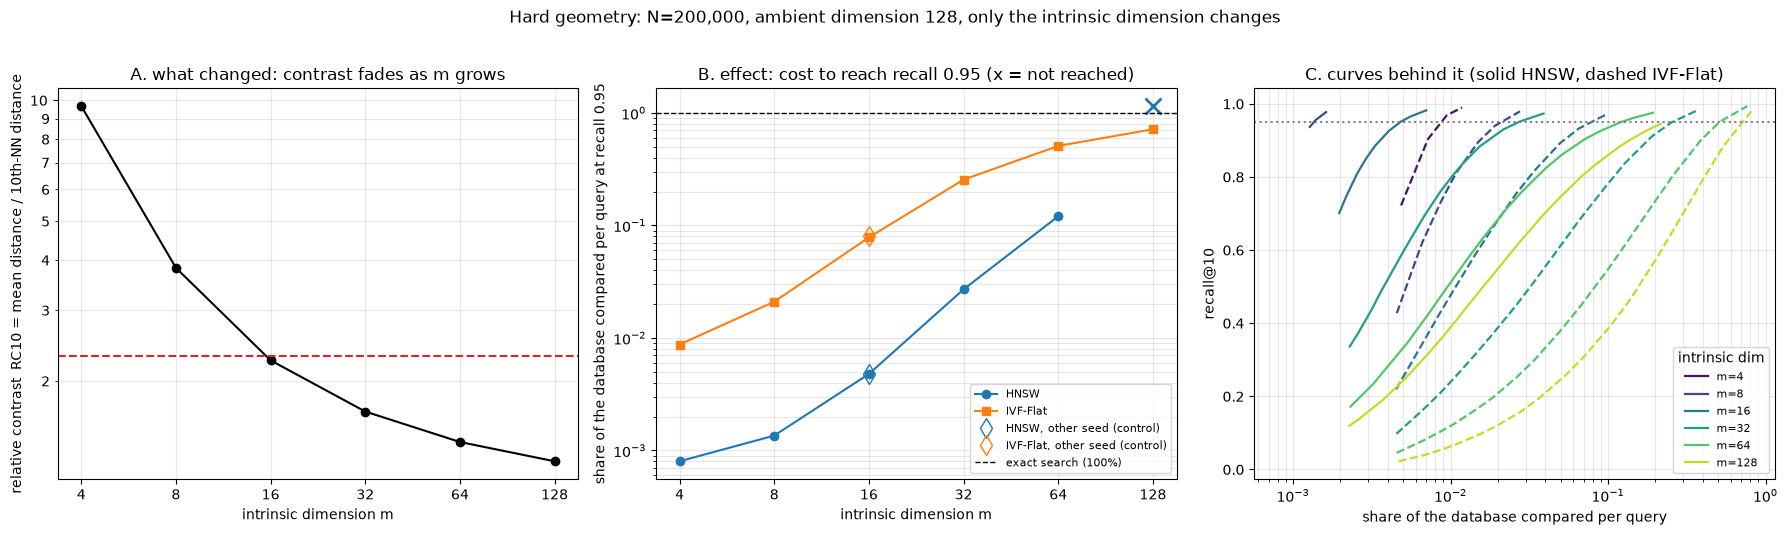

In [15]:
"""
This cell draws the main figure of the experiment (three panels: geometry, cost to reach recall 0.95, and full recall-vs-work curves) and saves it to data/processed/plots/part4_main.png.
"""
import os
os.makedirs("./data/processed/plots", exist_ok=True)
S = main(SUM)
G = main(GEO)
colors = dict(zip(M_VALUES, plt.cm.viridis(np.linspace(0.05, 0.9, len(M_VALUES)))))

fig, ax = plt.subplots(1, 3, figsize=(18, 5.2))

# A: geometry
ax[0].plot(G["m"], G["rc10"], "ko-", label="generated data")
ax[0].axhline(SIFT_GEO["rc10"], color="tab:red", ls="--", label=f"real SIFT (est. dim {SIFT_GEO['lid']:.0f})")
ax[0].set_xscale("log", base=2); ax[0].set_yscale("log")
ax[0].set_xticks(list(M_VALUES)); ax[0].set_xticklabels(M_VALUES)
from matplotlib.ticker import FuncFormatter
ax[0].yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}")); ax[0].yaxis.set_minor_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
ax[0].set_xlabel("intrinsic dimension m"); ax[0].set_ylabel("relative contrast  RC10 = mean distance / 10th-NN distance")
ax[0].set_title("A. what changed: contrast fades as m grows")

# B: cost at recall 0.95
cap = 1.15
for name, mk, col in (("HNSW", "o-", "tab:blue"), ("IVF-Flat", "s-", "tab:orange")):
    g = S[S["index"] == name].sort_values("m")
    ok = g[g["reached"]]
    ax[1].plot(ok["m"], ok["work_frac95"], mk, color=col, label=name)
    miss = g[~g["reached"]]
    ax[1].plot(miss["m"], [cap] * len(miss), "x", color=col, ms=11, mew=2)
ctrl = SUM[SUM["try"].str.startswith("Control")]
for name, col in (("HNSW", "tab:blue"), ("IVF-Flat", "tab:orange")):
    c = ctrl[(ctrl["index"] == name) & ctrl["reached"]]
    ax[1].plot(c["m"], c["work_frac95"], "d", color=col, mfc="none", ms=10, label=f"{name}, other seed (control)")
ax[1].axhline(1.0, color="k", ls="--", lw=1, label="exact search (100%)")
ax[1].set_xscale("log", base=2); ax[1].set_yscale("log")
ax[1].set_xticks(list(M_VALUES)); ax[1].set_xticklabels(M_VALUES)
ax[1].set_xlabel("intrinsic dimension m"); ax[1].set_ylabel("share of the database compared per query at recall 0.95")
ax[1].set_title("B. effect: cost to reach recall 0.95 (x = not reached)")
ax[1].legend(fontsize=8)

# C: curves
R = main(RES)
for m in M_VALUES:
    for name, ls in (("HNSW", "-"), ("IVF-Flat", "--")):
        g = R[(R["index"] == name) & (R["m"] == m)].sort_values("work_frac")
        ax[2].plot(g["work_frac"], g["recall"], ls, color=colors[m], lw=1.6, label=f"m={m}" if name == "HNSW" else None)
ax[2].axhline(TARGET, color="grey", ls=":")
ax[2].set_xscale("log"); ax[2].set_xlabel("share of the database compared per query"); ax[2].set_ylabel("recall@10")
ax[2].set_title("C. curves behind it (solid HNSW, dashed IVF-Flat)")
ax[2].legend(fontsize=8, title="intrinsic dim")

for a in ax:
    a.grid(alpha=0.3, which="both")
fig.suptitle(f"Hard geometry: N={N:,}, ambient dimension {D}, only the intrinsic dimension changes", y=1.02)
fig.tight_layout()
fig.savefig("./data/processed/plots/part4_main.png", dpi=150, bbox_inches="tight")
plt.show()

### Supporting figure: why IVF-Flat degrades (not the main figure)

For each setting, the share of true neighbours whose cell is among the `nprobe` nearest centroids. This curve **is** the IVF-Flat recall curve, so it shows where the failure comes from: with high *m* the neighbours sit in cells whose centroids are far down the ranking. The dots are the recall actually measured by the index, which should lie on the curve (prediction P8).

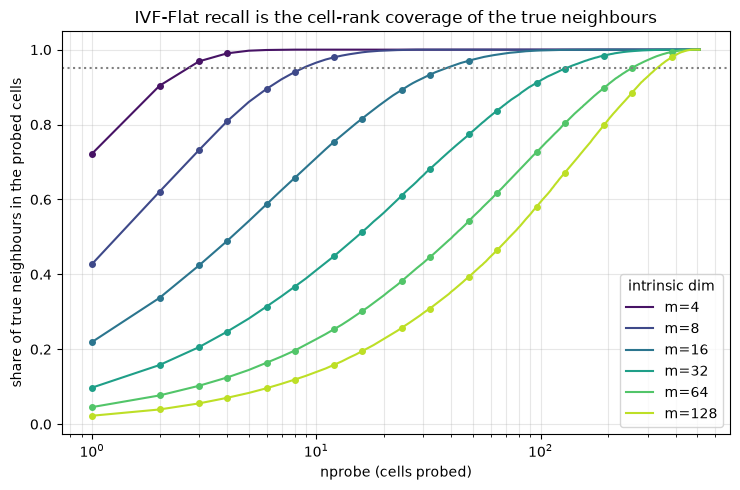

In [16]:
"""
This cell plots, for every setting, the share of true neighbours covered by the nprobe nearest cells (line) together with the recall measured by the index (dots), as a check and as the mechanism behind the IVF-Flat curves.
"""
fig, ax = plt.subplots(figsize=(7.5, 5))
for (tr, m, seed), ranks in RANKS.items():
    if tr.startswith("Control"):
        continue
    p = np.arange(1, NLIST + 1)
    cov = np.array([(ranks <= q).mean() for q in p])
    ax.plot(p, cov, color=colors[m], label=f"m={m}")
    g = RES[(RES["index"] == "IVF-Flat") & (RES["try"] == tr)]
    ax.plot(g["param"], g["recall"], "o", color=colors[m], ms=4)
ax.set_xscale("log"); ax.set_xlabel("nprobe (cells probed)"); ax.set_ylabel("share of true neighbours in the probed cells")
ax.axhline(TARGET, color="grey", ls=":"); ax.grid(alpha=0.3, which="both"); ax.legend(title="intrinsic dim")
ax.set_title("IVF-Flat recall is the cell-rank coverage of the true neighbours")
fig.tight_layout()
fig.savefig("./data/processed/plots/part4_ivf_mechanism.png", dpi=150)
plt.show()

## Did the results support the hypothesis?

Each prediction in `hypothesis_part4.md` is evaluated below with exactly the thresholds that were committed before the run. The verdicts are automatic and mechanical: the discussion of *why* a prediction held or failed belongs in the report. A prediction that cannot be evaluated (for example because a value is missing) is reported as such and not counted as supported.

In [17]:
"""
This cell checks the eight pre-registered predictions with the thresholds fixed in hypothesis_part4.md and prints a verdict for each, with the measured values.
"""
M = list(M_VALUES)
Sm = SUM[~SUM["try"].str.startswith("Control")]
Gm = GEO[~GEO["try"].str.startswith("Control")].set_index("m")

def wf(index, m):
    r = Sm[(Sm["index"] == index) & (Sm["m"] == m)].iloc[0]
    return r["work_frac95"] if r["reached"] else np.inf          # not reached = more expensive than anything measured

def ms(index, m):
    r = Sm[(Sm["index"] == index) & (Sm["m"] == m)].iloc[0]
    return r["ms95"] if r["reached"] else np.inf

def non_decreasing(vals, tol=0.10):
    return all(b >= a * (1 - tol) for a, b in zip(vals, vals[1:]))

verdicts = []
def verdict(pid, ok, detail):
    verdicts.append((pid, "SUPPORTED" if ok else "NOT SUPPORTED", detail))

# P1
lid = [Gm.loc[m, "lid"] for m in M]; rc = [Gm.loc[m, "rc10"] for m in M]
verdict("P1", all(b > a for a, b in zip(lid, lid[1:])) and all(b < a for a, b in zip(rc, rc[1:])),
        f"LID {np.round(lid, 1).tolist()}, RC10 {np.round(rc, 2).tolist()}")
# P2
ratio = Gm.loc[4, "rc10"] / Gm.loc[128, "rc10"]
verdict("P2", ratio >= 5, f"RC10(m=4)/RC10(m=128) = {ratio:.1f}")
# P3
ivf = [wf("IVF-Flat", m) for m in M]
verdict("P3", ivf[0] <= 0.05 and ivf[-1] >= 0.50 and non_decreasing(ivf),
        "IVF work fraction " + ", ".join("not reached" if np.isinf(v) else f"{v:.2%}" for v in ivf))
# P4
hn = [wf("HNSW", m) for m in M]
verdict("P4", hn[0] <= 0.01 and hn[-1] >= 0.05 and non_decreasing(hn),
        "HNSW work fraction " + ", ".join("not reached" if np.isinf(v) else f"{v:.2%}" for v in hn))
# P5
below = all(h < i for h, i in zip(hn, ivf))
gap_lo = ivf[0] / hn[0]; gap_hi = (ivf[-1] / hn[-1]) if np.isfinite(hn[-1]) and np.isfinite(ivf[-1]) else np.nan
verdict("P5", below and np.isfinite(gap_hi) and gap_hi < gap_lo,
        f"HNSW cheaper at every m: {below}; IVF/HNSW work ratio {gap_lo:.1f} at m=4 and {gap_hi:.1f} at m=128")
# P6
ivf128 = ms("IVF-Flat", 128)
verdict("P6", ivf128 >= EXACT_MS,
        "IVF-Flat at m=128: " + ("not reached" if np.isinf(ivf128) else f"{ivf128:.2f} ms") + f" vs exact {EXACT_MS:.2f} ms")
# P7
ctrl_ok, ctrl_txt = True, []
for name in ("HNSW", "IVF-Flat"):
    a = Sm[(Sm["index"] == name) & (Sm["m"] == REF_M)].iloc[0]
    b = SUM[(SUM["index"] == name) & SUM["try"].str.startswith("Control")].iloc[0]
    if a["reached"] and b["reached"]:
        rel = abs(b["work_frac95"] - a["work_frac95"]) / a["work_frac95"]
        ctrl_ok &= rel < 0.15
        ctrl_txt.append(f"{name} {a['work_frac95']:.3%} vs {b['work_frac95']:.3%} ({rel:.1%} apart)")
    else:
        ctrl_ok = False; ctrl_txt.append(f"{name}: target not reached")
verdict("P7", ctrl_ok, "; ".join(ctrl_txt))
# P8
verdict("P8", gap.max() < 0.01, f"max |recall - cell-rank coverage| = {gap.max():.4f}")

print(f"{'id':<4}{'verdict':<15}measured")
for pid, v, d in verdicts:
    print(f"{pid:<4}{v:<15}{d}")
print(f"\n{sum(v == 'SUPPORTED' for _, v, _ in verdicts)} of {len(verdicts)} predictions supported")

id  verdict        measured
P1  SUPPORTED      LID [6.6, 8.5, 15.4, 26.6, 42.5, 66.1], RC10 [9.67, 3.83, 2.25, 1.68, 1.41, 1.26]
P2  SUPPORTED      RC10(m=4)/RC10(m=128) = 7.7
P3  SUPPORTED      IVF work fraction 0.87%, 2.10%, 7.83%, 25.54%, 50.91%, 71.60%
P4  SUPPORTED      HNSW work fraction 0.08%, 0.14%, 0.48%, 2.70%, 12.07%, not reached
P5  NOT SUPPORTED  HNSW cheaper at every m: False; IVF/HNSW work ratio 10.9 at m=4 and nan at m=128
P6  NOT SUPPORTED  IVF-Flat at m=128: 6.33 ms vs exact 9.52 ms
P7  SUPPORTED      HNSW 0.479% vs 0.477% (0.3% apart); IVF-Flat 7.825% vs 7.978% (1.9% apart)
P8  SUPPORTED      max |recall - cell-rank coverage| = 0.0000

6 of 8 predictions supported


## Saving the results

In [18]:
"""
This cell saves the sweep points, the summary at recall 0.95 and the geometry table as csv files in data/processed, together with the hypothesis verdicts.
"""
print("saved:", save_df(RES, "results_part4_sweeps.csv"))
print("saved:", save_df(SUM, "results_part4_summary.csv"))
print("saved:", save_df(GEO, "results_part4_geometry.csv"))
print("saved:", save_df(pd.DataFrame(verdicts, columns=["prediction", "verdict", "measured"]), "results_part4_verdicts.csv"))

saved: ./data/processed/results_part4_sweeps.csv
saved: ./data/processed/results_part4_summary.csv
saved: ./data/processed/results_part4_geometry.csv
saved: ./data/processed/results_part4_verdicts.csv


## Report skeleton (at most one page, one main figure)

Fill in from the output above; the main figure is `data/processed/plots/part4_main.png`.

1. **What I changed.** The intrinsic dimension *m* of generated data (4 to 128) at fixed N = 200,000, ambient dimension 128, vector scale, noise level, index parameters and sweep grids. One property, six settings, plus a seed-repeat control at *m* = 16.
2. **What happened.** The cost of reaching recall 0.95 for each index (panel B): the numbers at *m* = 4, 16 and 128, which index degraded more, and whether either stopped reaching 0.95.
3. **The mechanism.** Panel A (contrast fades, real SIFT sits around *m* ~ ...) and the cell-rank figure for IVF-Flat; for HNSW, the growth of `efSearch` and of distances computed per query. Connect them: IVF-Flat's recall *is* the share of neighbours in the probed cells; HNSW's walk has less gradient to follow.
4. **Was the hypothesis supported?** Quote the verdict table, say which predictions failed and what the failure means. State plainly that the hypothesis file was committed before the first run (give the commit hash printed by the first cell), or that it was not.
5. **What I did not test.** Listed below.

**Not tested** (keep what applies):
- IVF-PQ, whose failure mode (quantisation error) interacts differently with intrinsic dimension.
- Other geometry knobs: cluster tightness, cluster imbalance, near-duplicates; and the ambient dimension separately from the intrinsic one.
- Other values of `M`, `efConstruction`, `nlist`: the parameters were held fixed by design, so a better-tuned index (for example a much larger `nlist` or `M`) might move the curves.
- Other database sizes (Part 3 covers scaling on real data) and the angular metric.
- Only one seed repeat, at the reference setting; error bars at every setting would need more.
- Latency was measured on one machine; distance computations, which do not depend on hardware, carry the conclusions.